# Canny Edge Detection
You are given an image of dolphin to detect the edge of this dolphin. For this section, experiments will be performed on the ’dolphin.png’ image.

 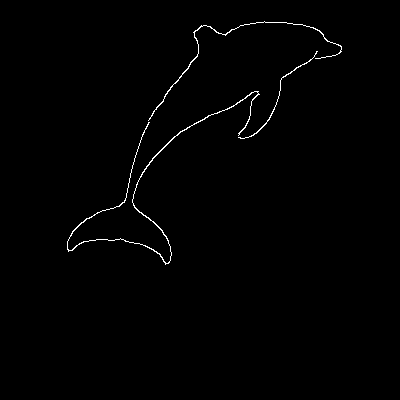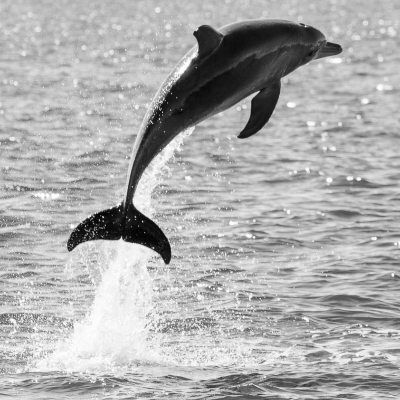


1.	The 3 main hyperparameters of Canny Edge detection are the Gaussian Smoothing Kernel size (K), and the Lower (L) and Higher (H) Thresholds used for Hysteresis. In this section, we will observe the effect of changing these hyperparameters. You will experiment on 3 different values for all 3 parameters (K = 3,7,11, L = 50,100,150, H = 100,150,200). Vary the values of each hyper-parameter and keep other hyper-parameters constant. Do this procedure for all combination of hyper-parameters mentioned above. This should results in total 27 triplets of hyper-parameters. E.g., (K,L,H) = (3,50,100), (7,100,150), (11,150,200), ….
* Use the sigma value of the Gaussian kernel (or set 0 if you use OpenCV GaussianBlur or getGaussianKernel) and do not use fixed sigma value like 1:
sigma = 0.3*((K-1)*0.5 - 1) + 0.8


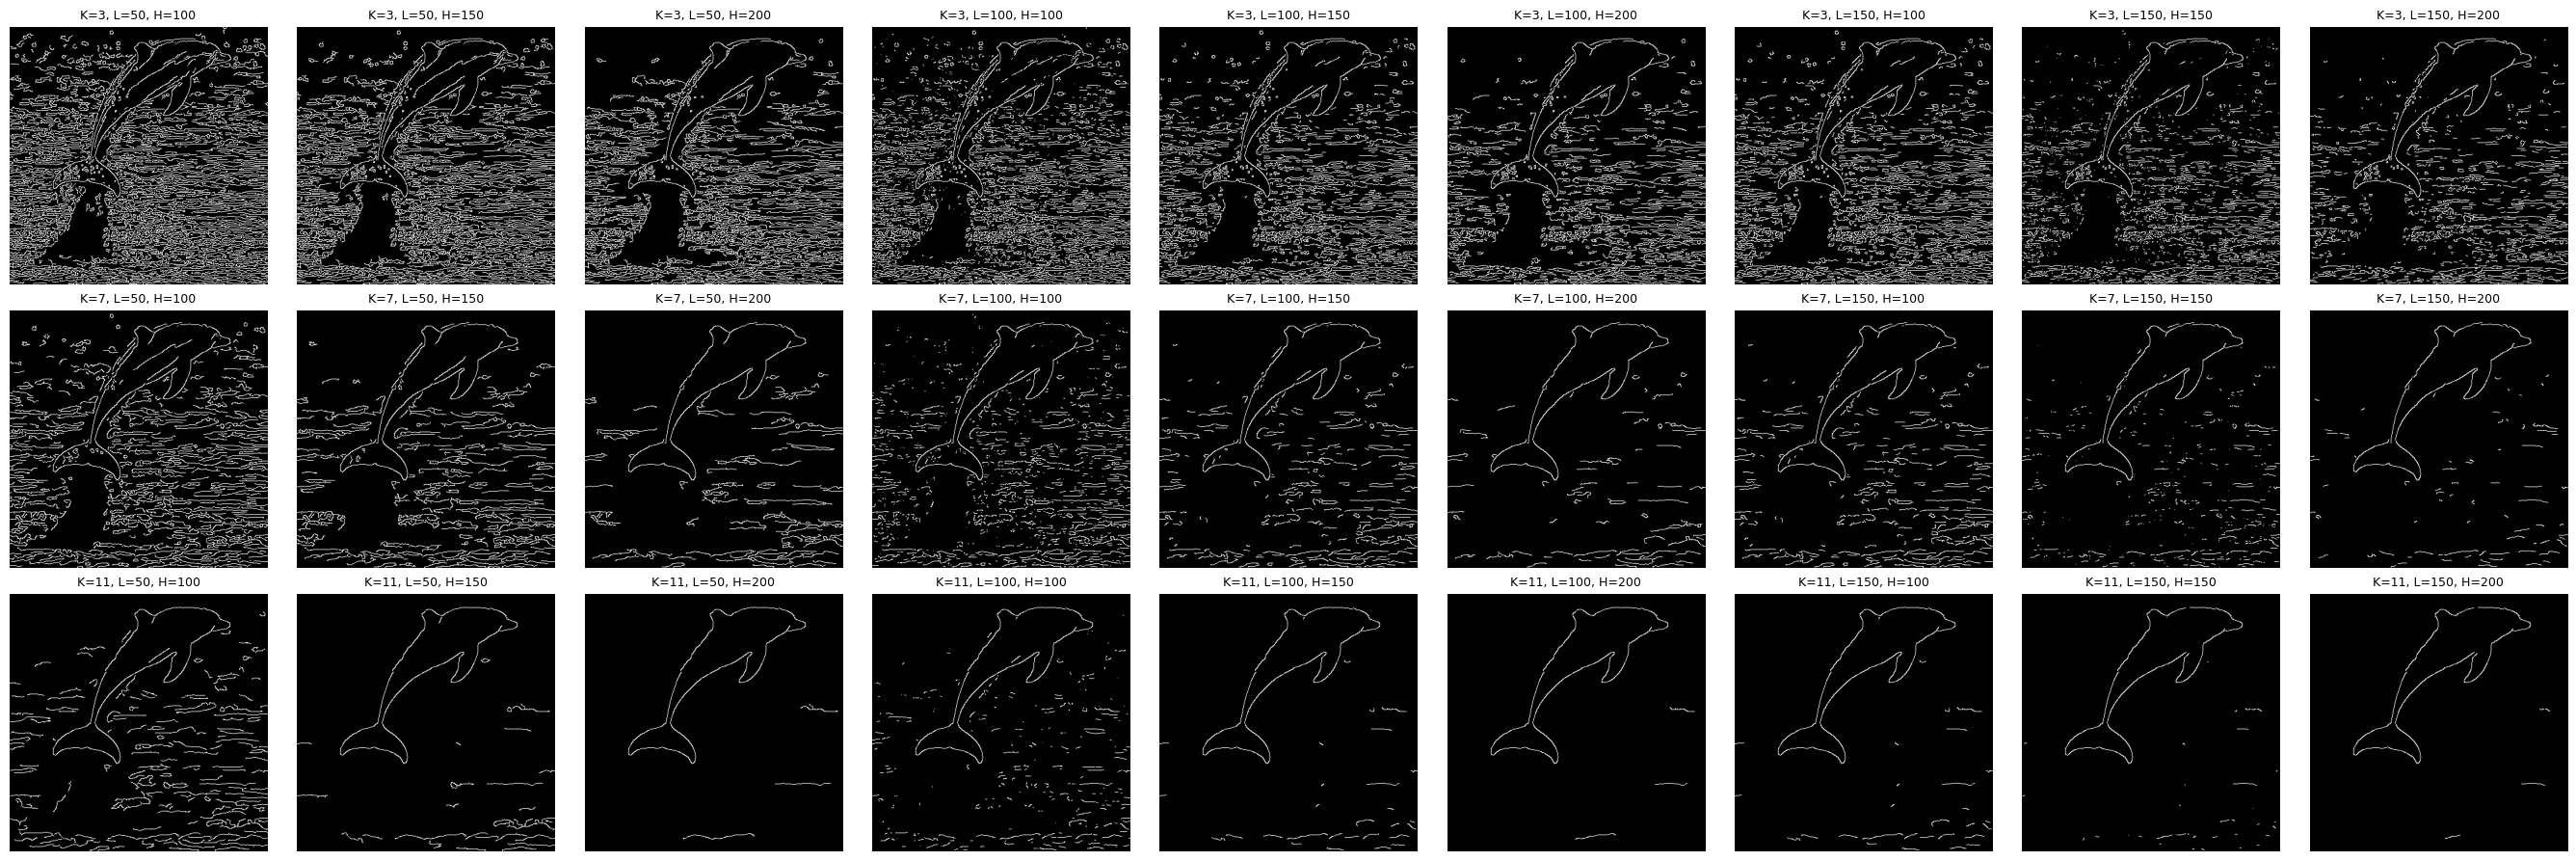

In [4]:
#Modules
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Input
dol = cv2.imread("dolphin.png", cv2.IMREAD_GRAYSCALE)
ref = cv2.imread("dolphin_edge.png", cv2.IMREAD_GRAYSCALE)

Ks, Ls, Hs = (3, 7, 11), (50, 100, 150), (100, 150, 200)
sigma = lambda K: 0.3 * ((K - 1) * 0.5 - 1) + 0.8     

def canny(K, L, H):
    blur = cv2.GaussianBlur(dol, (K, K), sigma(K))
    return cv2.Canny(blur, L, H)

combos = [(K, L, H) for K in Ks for L in Ls for H in Hs]
fig, axes = plt.subplots(3, 9, figsize=(27, 9))

#output
for ax, (K, L, H) in zip(axes.ravel(), combos):
    ax.imshow(canny(K, L, H), cmap="gray")
    ax.set_title(f"K={K}, L={L}, H={H}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

2.	Analyze how changes to the values of each hyperparameter K, L, and H affect the overall edge detection. Does increasing K or adjusting the thresholds influence the prominence or suppression of edges?

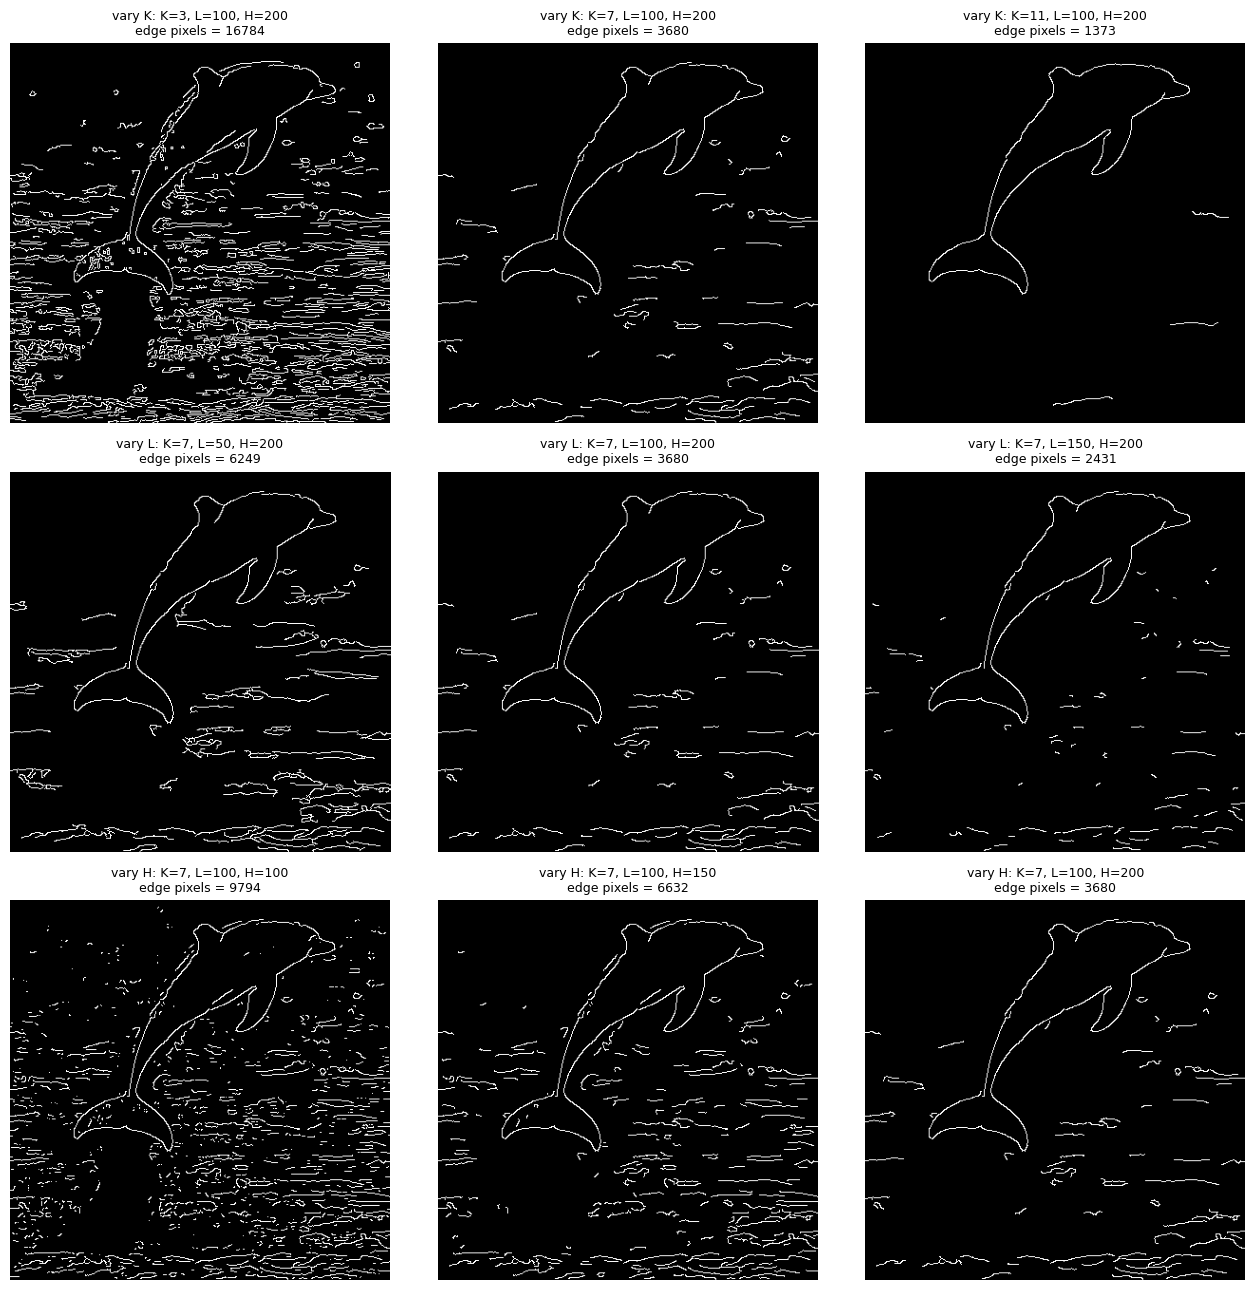

In [5]:
#Modules
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Input
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
sets = [
    ("K", [(K, 100, 200) for K in Ks]),     # vary K, L=100, H=200
    ("L", [(7, L, 200) for L in Ls]),       # vary L, K=7, H=200
    ("H", [(7, 100, H) for H in Hs]),       # vary H, K=7, L=100
]

#Output
for r, (name, trip) in enumerate(sets):
    for c, (K, L, H) in enumerate(trip):
        e = canny(K, L, H)
        axes[r, c].imshow(e, cmap="gray")
        axes[r, c].set_title(f"vary {name}: K={K}, L={L}, H={H}\nedge pixels = {(e > 0).sum()}", fontsize=9)
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

##Observation

Increasing the value of K (the kernel size) makes the smoothing stronger. This smooths out details like water texture, splashes and noise. As a result fewer edge pixels remain. For example when K is set to 3 the water ripples produce a number of edges—11,813 edge pixels when L is 150 and H is 200.. When K increases to 11 the number of edge pixels drops to 1,271. The dolphin’s outline becomes less precise because of the extra blur but it stays clean and well-defined.

The values of L and H—known as hysteresis thresholds—also play a role. Raising H means fewer pixels qualify as edges. Raising L makes it harder for weak edges to connect to ones. Both actions help suppress textured edges. So the edges from the water disappear first while the stronger edges of the dolphin stay. For example with K = 11 increasing the thresholds from L = 50 and H = 100 (which gives 7,713 edge pixels) to L = 150 and H = 200 (1,271 edge pixels) removes most of the clutter. When L and H are low the result includes much detail—everything, including water texture—and becomes very noisy.

Does increasing K. Adjusting the thresholds change the prominence or suppression of edges? Yes. Increasing K or raising L and H suppresses edges—like texture and noise—and keeps the strong ones. Lowering them makes more edges stand out. That includes edges that are not important like those, from water ripples. So the choice of K and the thresholds controls how much detail is kept and how clean the final image looks.

3.	Determine the optimal values of K,L, and H that isolate only the edges in the dolphin in ‘dolphin_edge.png’. Provide your observations and reasoning behind selecting these specific values.

Top 5 combos: (F1, precision, recall), (K, L, H)
  F1=0.965  P=0.93  R=1.00  (11, 150, 200)
  F1=0.934  P=0.88  R=1.00  (11, 100, 200)
  F1=0.900  P=0.82  R=1.00  (11, 150, 150)
  F1=0.891  P=0.80  R=1.00  (11, 50, 200)
  F1=0.777  P=0.64  R=1.00  (11, 100, 150)


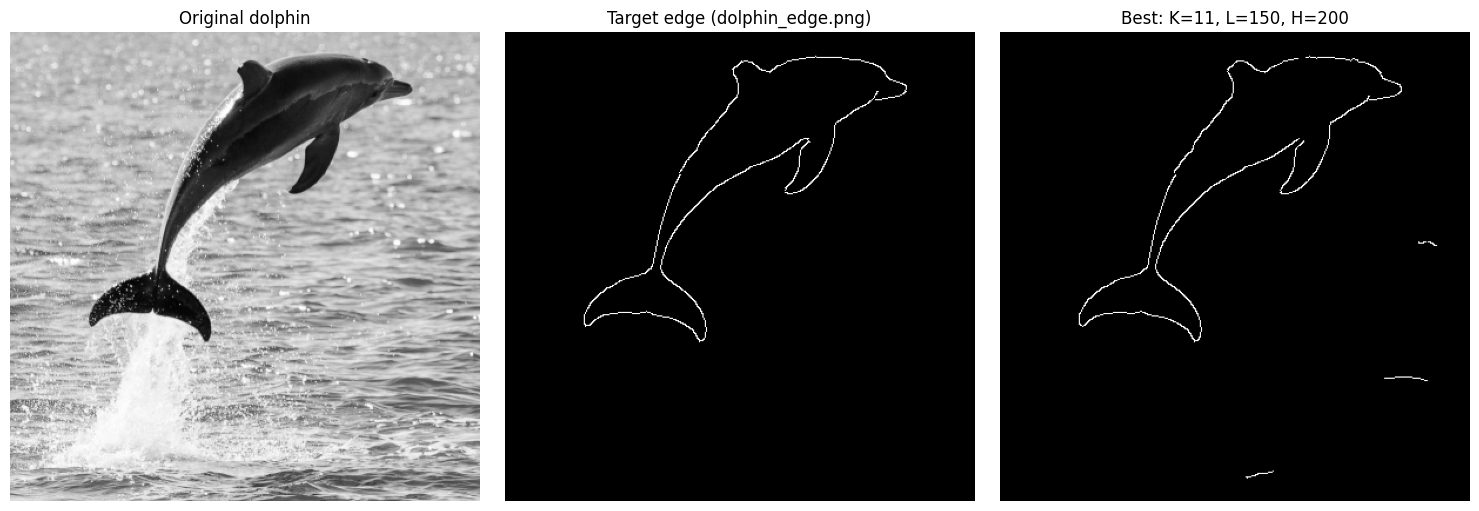

In [6]:
#Modules
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Input
def f1_score(pred, gt, tol=3):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    p, g = pred > 0, gt > 127
    prec = (p & (cv2.dilate(g.astype(np.uint8), k) > 0)).sum() / max(p.sum(), 1)
    rec  = (g & (cv2.dilate(p.astype(np.uint8), k) > 0)).sum() / max(g.sum(), 1)
    return 2 * prec * rec / max(prec + rec, 1e-9), prec, rec

scores = sorted(((f1_score(canny(*c), ref), c) for c in combos), key=lambda t: t[0][0], reverse=True)
print("Top 5 combos: (F1, precision, recall), (K, L, H)")
for (f, p, r), c in scores[:5]:
    print(f"  F1={f:.3f}  P={p:.2f}  R={r:.2f}  {c}")

K, L, H = scores[0][1]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, im, t in zip(axes, [dol, ref, canny(K, L, H)],
                    ["Original dolphin", "Target edge (dolphin_edge.png)", f"Best: K={K}, L={L}, H={H}"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout()
plt.show()

##Observation

The best triplet is K = 11 L = 150, H = 200 with F1 ≈ 0.96 (precision 0.93 recall 1.0) against dolphin_edge.png. The runners‑ups are K = 11 L = 100 H = 200 (F1 ≈ 0.93). K = 11 L = 150, H = 150 (F1 ≈ 0.90).

Recall is 1.0 for every combination because the dolphin’s strong outline is always found. Therefore the only difference between combinations is precision. Precision tells how many false edges are produced.

A large K = 11 blurs away the water texture and sun glints.

High thresholds, L = 150 and H = 200 keep the strong contrast along the dolphin’s body and tail. They drop the edges that appear in the water.

The small kernel K = 3 detects every ripple, as an edge. As a result every K = 3 setting is poor (F1 ≤ 0.21).